In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Configure visual settings
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [2]:
# load dataset
df = pd.read_csv("/content/Food_Inspections.csv", low_memory=False)
print(f"Raw rows: {len(df):,}")

# turn date strings to datetime
df["Inspection Date"] = pd.to_datetime(df["Inspection Date"], format="%m/%d/%Y")

# filter out inspections that weren't completed: Out of Business, No Entry, Not Ready, Business Not Located
keep = ["Pass", "Pass w/ Conditions", "Fail"]
df = df[df["Results"].isin(keep)].copy()

# filter out COVID-era rows, 2021 incomplete and dataset documention mentions changed practices
df = df[df["Inspection Date"] < "2020-03-01"]

# drop rows without license/id
df = df[df["License #"].notna() & (df["License #"] != 0)].copy()
df["License #"] = df["License #"].astype(int)

# keep the three risk levels, drop all/NaN
risk_map = {"Risk 1 (High)": 1, "Risk 2 (Medium)": 2, "Risk 3 (Low)": 3}
df["risk_level"] = df["Risk"].map(risk_map)
df = df.dropna(subset=["risk_level"])

# group facility type
def group_facility(s):
    s = str(s).lower()
    if "daycare" in s or "children" in s or "day care" in s:
        return "Daycare / Children's"
    if "school" in s:
        return "School"
    if "restaurant" in s:
        return "Restaurant"
    if "grocery" in s:
        return "Grocery Store"
    if "bakery" in s:
        return "Bakery"
    if "long term" in s or "assisted" in s or "hospital" in s:
        return "Care facility"
    if "catering" in s or "mobile" in s:
        return "Catering / Mobile"
    return "Other"

df["facility"] = df["Facility Type"].fillna("Unknown").map(group_facility)
print("Facility Counts after grouping:")
print(df["facility"].value_counts())

# standardize inspection type, flag re-inspections
df["insp_type"] = df["Inspection Type"].str.strip().str.title()
df["is_reinspection"] = df["insp_type"].str.contains("Re-Inspection", na=False).astype(int)
top_type = df["insp_type"].value_counts().head(6).index
df["insp_type"] = np.where(df["insp_type"].isin(top_type), df["insp_type"], "Other")

# get target label
# Fail (1) vs Pass or Pass w/ Conditions (0)
df["fail"] = (df["Results"] == "Fail").astype(int)

# sort
df = df.sort_values(["License #", "Inspection Date", "Inspection ID"])

# get histories
df["prior_inspections"] = df.groupby("License #").cumcount()
df["prior_fails"] = df.groupby("License #")["fail"].cumsum() - df["fail"]

df["prior_fail_rate"] = np.where(
    df["prior_inspections" ] > 0,
    df["prior_fails"] / df["prior_inspections"],
    0.0
)

# first inspections
df["first_in_data"] = (df["prior_inspections"] == 0).astype(int)

# days since previous inspection, capped to reduce extreme outlier impact
MAX_GAP = 730  # 2 years, longer gaps are all treated the same
df["prev_date"] = df.groupby("License #")["Inspection Date"].shift(1)
df["days_since_last"] = (df["Inspection Date" ] - df["prev_date"]).dt.days.clip(upper=MAX_GAP)

df["month"] = df["Inspection Date"].dt.month.astype(str)
df["year"] = df["Inspection Date"].dt.year

# save inspections for analysis (used in debugging/diagnosing errors downstream)
history_ids = set(df["Inspection ID"])

# drop re-inspections
df = df[df["is_reinspection"] == 0].copy()
modeled_ids = set(df["Inspection ID"])

# fill missing gaps from training data only
median_gap = df.loc[df["year"] <= 2017, "days_since_last"].median()
df["days_since_last"] = df["days_since_last"].fillna(median_gap)

# select features
cat_features = ["facility", "insp_type", "month"]
num_features = ["risk_level", "prior_inspections", "prior_fail_rate", "days_since_last", "first_in_data"]
features = cat_features + num_features

print(f"\nClean modeling rows: {len(df):,}  |  fail rate: {df['fail'].mean():.1%}")
print(df["Results"].value_counts())

Raw rows: 221,468
Facility Counts after grouping:
facility
Restaurant              119403
Grocery Store            22775
School                   12520
Daycare / Children's      8958
Other                     5076
Catering / Mobile         2615
Bakery                    2596
Care facility             2138
Name: count, dtype: int64

Clean modeling rows: 138,256  |  fail rate: 25.9%
Results
Pass                  77666
Fail                  35745
Pass w/ Conditions    24845
Name: count, dtype: int64


In [3]:
# split data: Train <= 2017 (112,282 rows), Test >= 2018 (25,974 rows)
# about 80/20 split, doesn't let date cause impact by splitting on date
train = df[df["year"] <= 2017]
test = df[df["year"] >= 2018]
X_train, y_train = train[features], train["fail"]
X_test, y_test = test[features], test["fail"]
print(f"Train: {len(train):,} (2010-2017)   Test: {len(test):,} (2018-Feb 2020)")
print(f"Fail rate train {y_train.mean():.1%} | test {y_test.mean():.1%}\n")

Train: 112,282 (2010-2017)   Test: 25,974 (2018-Feb 2020)
Fail rate train 25.8% | test 26.0%



In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# scale and encode
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat_features),
    ("num", StandardScaler(), num_features),
])


# 74% pass imbalance so use class_weight balanced to get higher loss weights to Fail records
model = Pipeline([
    ("pre", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

# fit on the training set
model.fit(X_train, y_train)

# make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# build the Dummy Baseline (always predicts the most frequent class: Pass)
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_dummy_pred = dummy.predict(X_test)

# evaluate comparison
metrics_model = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (Fail)": precision_score(y_test, y_pred),
    "Recall (Fail)": recall_score(y_test, y_pred),
    "F1-Score (Fail)": f1_score(y_test, y_pred)
}

metrics_dummy = {
    "Accuracy": accuracy_score(y_test, y_dummy_pred),
    "Precision (Fail)": precision_score(y_test, y_dummy_pred, zero_division=0),
    "Recall (Fail)": recall_score(y_test, y_dummy_pred, zero_division=0),
    "F1-Score (Fail)": f1_score(y_test, y_dummy_pred, zero_division=0)
}

comparison_df = pd.DataFrame([metrics_model, metrics_dummy], index=["Logistic Regression (Balanced)", "Dummy Baseline (Predict Pass)"]).round(3)
display(comparison_df)

test_fail_rate = y_test.mean()
base_acc = metrics_dummy["Accuracy"]
lift = metrics_model["Precision (Fail)"] / test_fail_rate
flag_rate = (y_pred == 1).mean()

,Accuracy,Precision (Fail),Recall (Fail),F1-Score (Fail)
Logistic Regression (Balanced),0.613,0.34,0.52,0.411
Dummy Baseline (Predict Pass),0.740,0.00,0.00,0.000


In [5]:
# check other models to see if theres a better option

!pip install lazypredict -q

from lazypredict.Supervised import LazyClassifier
from sklearn.model_selection import train_test_split
import pandas as pd

# preprocess the data
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

if hasattr(X_train_trans, "toarray"):
    X_train_trans = X_train_trans.toarray()
    X_test_trans = X_test_trans.toarray()

# subsample the training data to 5,000 rows, not enough RAM
_, X_sub, _, y_sub = train_test_split(
    X_train_trans, y_train, test_size=5000, random_state=42, stratify=y_train
)

# use lazy classifier on subset
clf = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None)
models, predictions = clf.fit(X_sub, X_test_trans, y_sub, y_test)

# summary table comparing models
print(models)

                               Accuracy  Balanced Accuracy   ROC AUC  \
Model                                                                  
NearestCentroid                0.629976           0.563761  0.570587   
GaussianNB                     0.669631           0.543845  0.565647   
BernoulliNB                    0.696966           0.536508  0.570332   
QuadraticDiscriminantAnalysis  0.671017           0.534114  0.541560   
XGBClassifier                  0.702780           0.518620  0.560631   
Perceptron                     0.633595           0.518442  0.531333   
LGBMClassifier                 0.721106           0.516777  0.574175   
BaggingClassifier              0.691769           0.515602  0.548244   
KNeighborsClassifier           0.700393           0.514508  0.533322   
RandomForestClassifier         0.701009           0.510504  0.557237   
ExtraTreesClassifier           0.674752           0.509247  0.544700   
LinearDiscriminantAnalysis     0.738816           0.508944  0.60

In [6]:
# cross validate
gkf = GroupKFold(n_splits=5)

cv = cross_validate(model, X_train, y_train, groups=train["License #"], cv=gkf,
                    scoring=["accuracy", "precision", "recall", "f1"])

print(f"  Accuracy:  {cv['test_accuracy'].mean():.3f} ± {cv['test_accuracy'].std():.3f}")
print(f"  Precision: {cv['test_precision'].mean():.3f} ± {cv['test_precision'].std():.3f}")
print(f"  Recall:    {cv['test_recall'].mean():.3f} ± {cv['test_recall'].std():.3f}")
print(f"  F1-Score:  {cv['test_f1'].mean():.3f} ± {cv['test_f1'].std():.3f}")

  Accuracy:  0.616 ± 0.005
  Precision: 0.349 ± 0.006
  Recall:    0.559 ± 0.007
  F1-Score:  0.429 ± 0.005


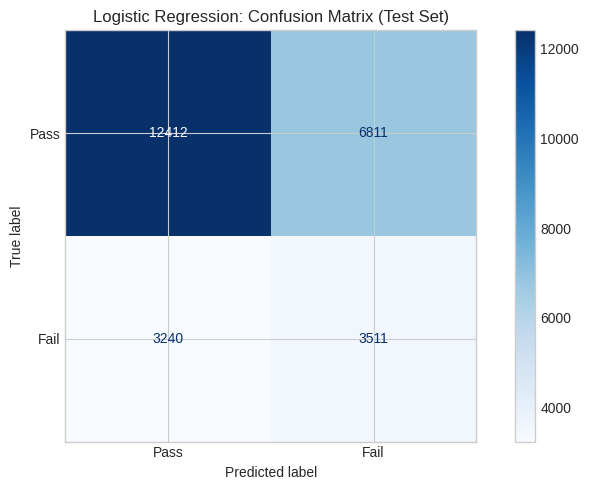

Top 5 Features indicating failure (Positive Coefficients):
num__prior_fail_rate        0.25
num__first_in_data          0.29
cat__insp_type_License      0.32
cat__insp_type_Complaint    0.36
cat__facility_Other         0.43
dtype: float64

Top 5 Features indicating passing (Negative Coefficients):
cat__facility_Daycare / Children's   -0.38
cat__insp_type_Other                 -0.36
cat__insp_type_Canvass               -0.29
cat__facility_Care facility          -0.25
cat__month_12                        -0.18
dtype: float64


In [7]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Pass", "Fail"]).plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression: Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

# key coefficients show importance of features
names = model.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(model.named_steps["model"].coef_[0], index=names).sort_values()

print("Top 5 Features indicating failure (Positive Coefficients):")
print(coefs.tail(5).round(2))
print("\nTop 5 Features indicating passing (Negative Coefficients):")
print(coefs.head(5).round(2))

In [8]:
# get 5 incorrect predictions
t = test.copy()
t["pred"] = y_pred
t["p_fail"] = y_prob

cols = ["Inspection ID", "License #", "DBA Name", "facility", "Inspection Type", "insp_type", "risk_level",
        "prior_inspections", "prior_fail_rate", "days_since_last", "Results", "p_fail"]

# False Negatives: actual Fail (1), predicted Pass (0)
fn = t[(t["fail"] == 1) & (t["pred"] == 0)].sort_values("p_fail").head(3)

# False Positives: actual Pass (0), predicted Fail (1)
fp = t[(t["Results" ] == "Pass") & (t["pred"] == 1)].sort_values("p_fail", ascending=False).head(2)

errors = pd.concat([fn, fp])
display(errors[cols].round(3))

# find features impact prediction
pre = model.named_steps["pre"]
coef = model.named_steps["model"].coef_[0]
names = pre.get_feature_names_out()

def top_drivers(idx, k=4):
    row = pre.transform(test.loc[[idx], features])
    row = row.toarray()[0] if hasattr(row, "toarray") else row[0]
    contrib = pd.Series(row * coef, index=names)
    return contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(k).round(2)

for idx in errors.index:
    print(f"\n{t.loc[idx, 'DBA Name']} (p_fail={t.loc[idx, 'p_fail']:.2f}, actual: {t.loc[idx, 'Results']})")
    print(top_drivers(idx).to_string())

,Inspection ID,License #,DBA Name,facility,Inspection Type,insp_type,risk_level,prior_inspections,prior_fail_rate,days_since_last,Results,p_fail
26572,2356990,2487715,LINCOLN PARK PRESCHOOL & KINDERGARTEN,Daycare / Children's,Suspected Food Poisoning,Other,1.0,4,0.0,95.0,Fail,0.225
41055,2252867,2476421,"CREATIVE KIDZ LEARNING CENTER, INC.",Daycare / Children's,Canvass,Canvass,1.0,5,0.0,82.0,Fail,0.238
61902,2130098,2215523,BRICKTON MONTESSORI SCHOOL,Daycare / Children's,Canvass,Canvass,1.0,4,0.0,124.0,Fail,0.242
54698,2200932,2528929,AUNT MARTHA'S,Other,License,License,1.0,0,0.0,284.0,Pass,0.769
38128,2303358,2664795,FOODA - SHOPS AT NORTH BRIDGE,Other,License,License,2.0,0,0.0,284.0,Pass,0.760



LINCOLN PARK PRESCHOOL & KINDERGARTEN (p_fail=0.23, actual: Fail)
cat__facility_Daycare / Children's   -0.38
cat__insp_type_Other                 -0.36
num__first_in_data                   -0.17
num__prior_fail_rate                 -0.16

CREATIVE KIDZ LEARNING CENTER, INC. (p_fail=0.24, actual: Fail)
cat__facility_Daycare / Children's   -0.38
cat__insp_type_Canvass               -0.29
num__first_in_data                   -0.17
num__prior_fail_rate                 -0.16

BRICKTON MONTESSORI SCHOOL (p_fail=0.24, actual: Fail)
cat__facility_Daycare / Children's   -0.38
cat__insp_type_Canvass               -0.29
num__first_in_data                   -0.17
num__prior_fail_rate                 -0.16

AUNT MARTHA'S (p_fail=0.77, actual: Pass)
num__first_in_data        0.50
cat__facility_Other       0.43
cat__insp_type_License    0.32
num__prior_fail_rate     -0.16

FOODA - SHOPS AT NORTH BRIDGE (p_fail=0.76, actual: Pass)
num__first_in_data        0.50
cat__facility_Other       0.43
cat__ins